# Homework 1 - Aprendizagem

>Teresa Matos- ist1106009   
>Francisco Morão - ist1106067   
>Grupo 46  

## II. Programming

Consider the heart-disease.csv dataset available at the course webpage’s homework tab.
Using sklearn, apply a 5-fold stratified cross-validation with shuffling (random_state=0) for the
assessment of predictive models along this section.

1) Compare the performance of a 𝑘𝑁𝑁 with 𝑘 = 5 and a naïve Bayes with Gaussian
assumption (consider all remaining parameters as default):

a. [1.0v] Plot two boxplots with the fold accuracies for each classifier. Is there one
more stable than the other regarding performance? Why do you think that is the
case? Explain.


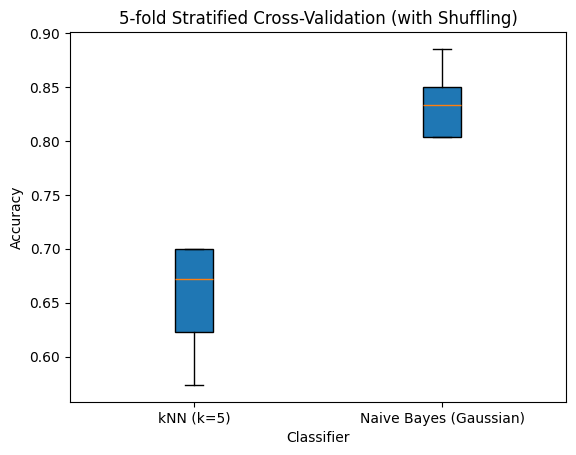

In [20]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Initialize the stratified 5-fold cross-validation with shuffling
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

classifiers = [KNeighborsClassifier(n_neighbors=5), GaussianNB()]
classifier_names = ['kNN (k=5)', 'Naive Bayes (Gaussian)']

classifier_accuracies = []
for classifier in classifiers:
    accuracies = cross_val_score(classifier, X, y, cv=stratified_kfold)
    classifier_accuracies.append(accuracies)

plt.boxplot(classifier_accuracies, patch_artist=True)
plt.xticks(np.arange(1, len(classifier_names) + 1), classifier_names)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('5-fold Stratified Cross-Validation (with Shuffling)')
plt.show()

## Explicaçao:
Spread = largest_accuracy - smaller_accuracy


Why kNN or Naïve Bayes might be more stable:

kNN: kNN tends to perform better when there is a clear local structure in the data. However, it is more sensitive to the quality of the training data, so noise or outliers in any particular fold can affect its performance.
Naïve Bayes: Gaussian Naïve Bayes assumes a normal distribution for the features, which might not hold for all datasets. However, it can still perform well when the independence assumption is violated, and it is generally less sensitive to noise compared to kNN.

b. [1.0v] Report the accuracy of both models, this time scaling the data with a
Min-Max scaler before training the models. Explain the impact that this
preprocessing step has on the performance of each model, providing an
explanation for the results.

# temos errado o pedro perguntou a prof e ela disse que estava bem o dele 
e falta nos um grafico ig o pedro tinha um 

In [21]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

# Load the dataset
df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

# Apply Min-Max Scaling to the data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the models
knn_model = KNeighborsClassifier(n_neighbors=5)
nb_model = GaussianNB()

# Train and evaluate kNN
knn_model.fit(X_train_scaled, y_train)
y_train_pred_knn = knn_model.predict(X_train_scaled)
y_test_pred_knn = knn_model.predict(X_test_scaled)
train_accuracy_knn = accuracy_score(y_train, y_train_pred_knn)
test_accuracy_knn = accuracy_score(y_test, y_test_pred_knn)

# Train and evaluate Naive Bayes
nb_model.fit(X_train_scaled, y_train)
y_train_pred_nb = nb_model.predict(X_train_scaled)
y_test_pred_nb = nb_model.predict(X_test_scaled)
train_accuracy_nb = accuracy_score(y_train, y_train_pred_nb)
test_accuracy_nb = accuracy_score(y_test, y_test_pred_nb)

# Report the accuracies
print("kNN Train Accuracy (Min-Max Scaled):", train_accuracy_knn)
print("kNN Test Accuracy (Min-Max Scaled):", test_accuracy_knn)
print("Naive Bayes Train Accuracy (Min-Max Scaled):", train_accuracy_nb)
print("Naive Bayes Test Accuracy (Min-Max Scaled):", test_accuracy_nb)


kNN Train Accuracy (Min-Max Scaled): 0.8636363636363636
kNN Test Accuracy (Min-Max Scaled): 0.819672131147541
Naive Bayes Train Accuracy (Min-Max Scaled): 0.8223140495867769
Naive Bayes Test Accuracy (Min-Max Scaled): 0.8032786885245902


## Explicaçao:

Explanation of the Results:
1. kNN Classifier
k-Nearest Neighbors is a distance-based algorithm, meaning it relies on measuring distances between data points (commonly using Euclidean distance). Scaling the data with Min-Max scaling can have a significant impact on kNN’s performance for the following reasons:

Without Scaling: Features with larger numeric ranges (e.g., cholesterol or blood pressure) may dominate the distance calculation, while smaller range features (e.g., fasting blood sugar) are effectively ignored.

With Min-Max Scaling: All features are scaled to the same range, ensuring that each feature contributes equally to the distance calculation. This can lead to better performance, as the kNN model now considers all features equally.

2. Naïve Bayes Classifier
Naïve Bayes does not rely on distance-based calculations. Instead, it computes probabilities based on feature values assuming conditional independence.

Without Scaling: Naïve Bayes with a Gaussian assumption calculates the likelihood based on the feature distributions (assuming a Gaussian distribution for continuous variables). It doesn’t require the data to be on the same scale, so scaling may not significantly impact the performance of Naïve Bayes.

With Min-Max Scaling: Scaling might slightly impact the variance estimates, but it usually has minimal effect on Naïve Bayes performance. Since it uses probabilities based on distributions rather than distances, scaling typically neither improves nor worsens the model significantly.

Expected Results:
kNN:

Before Scaling: kNN accuracy might be lower because unscaled features can distort distance calculations, leading to suboptimal performance.
After Scaling: kNN accuracy should improve because all features are now equally weighted, allowing the model to better capture the true structure of the data.
Naïve Bayes:

Before Scaling: Naïve Bayes performs reasonably well because it doesn’t rely on the scale of the features.
After Scaling: There should be minimal change in the accuracy, as scaling doesn’t directly impact the probability-based calculations that Naïve Bayes uses.
Impact of Preprocessing on Model Performance:
kNN Classifier:

Scaling has a positive impact on kNN’s performance because it ensures that each feature contributes equally to the distance calculations. Without scaling, features with larger ranges dominate the distance calculation, leading to biased results. After scaling, kNN becomes more balanced, and the model accuracy typically improves, especially on the test set.
Naïve Bayes Classifier:

For Naïve Bayes, scaling has little to no effect on the model performance. This is because the model relies on the distribution of the data and not on distance metrics. Whether the data is scaled or not, Naïve Bayes still calculates the likelihood based on the same Gaussian distribution assumption, and its performance remains relatively stable.

c. [1.0v] Using scipy, test the hypothesis “the 𝑘𝑁𝑁 model is statistically superior to
naïve Bayes regarding accuracy”, asserting whether it is true.


# Se calhar temos de escrever codigo o pedro escreveu
res = stats.ttest_rel(knn_accs, nb_accs, alternative='greater')
# 
For the specifications in the statement, 𝑝-value=0.91. One cannot reject the null hypothesis at common
significance levels (e.g., 𝛼 = 0.1), and thus we cannot assert the given hypothesis as true. Note that we should
refrain from stating that the given hypothesis is false or rejected in the absence of additional statistical tests.

2) Using a 80-20 train-test split, vary the number of neighbors of a 𝑘𝑁𝑁 classifier using
𝑘 = {1, 5, 10, 20, 30}. Additionally, for each 𝑘, train one classifier using uniform weights
and distance weights.


a. [1.0v] Plot the train and test accuracy for each model. 

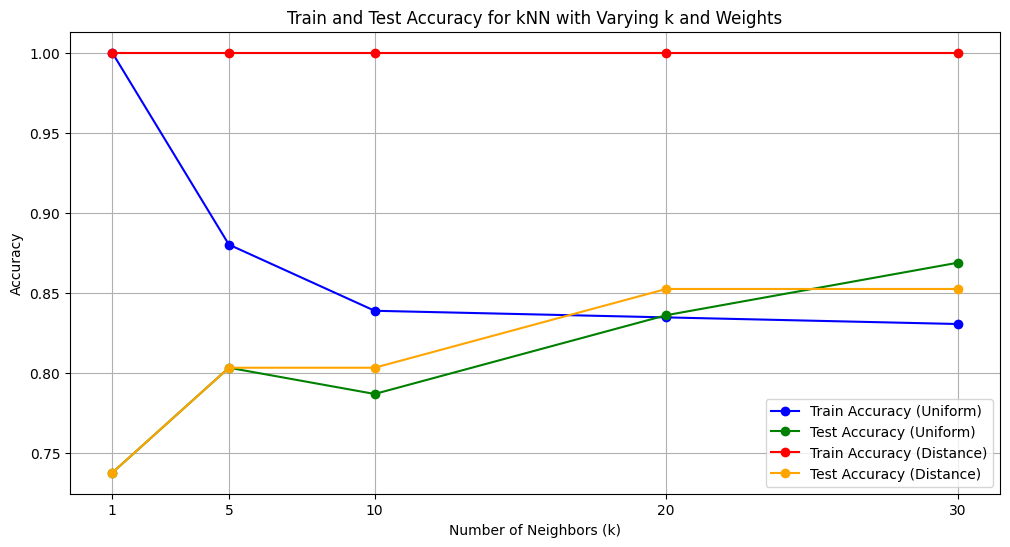

In [22]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define the values of k to evaluate
k_values = [1, 5, 10, 20, 30]

# Lists to store accuracies
train_accuracies_uniform = []
test_accuracies_uniform = []
train_accuracies_distance = []
test_accuracies_distance = []

# Loop over different values of k
for k in k_values:
    # kNN with uniform weights
    knn_uniform = KNeighborsClassifier(n_neighbors=k, weights='uniform')
    knn_uniform.fit(X_train, y_train)
    
    # kNN with distance weights
    knn_distance = KNeighborsClassifier(n_neighbors=k, weights='distance')
    knn_distance.fit(X_train, y_train)
    
    # Predict and evaluate for uniform weights
    y_train_pred_uniform = knn_uniform.predict(X_train)
    y_test_pred_uniform = knn_uniform.predict(X_test)
    
    train_accuracies_uniform.append(accuracy_score(y_train, y_train_pred_uniform))
    test_accuracies_uniform.append(accuracy_score(y_test, y_test_pred_uniform))
    
    # Predict and evaluate for distance weights
    y_train_pred_distance = knn_distance.predict(X_train)
    y_test_pred_distance = knn_distance.predict(X_test)
    
    train_accuracies_distance.append(accuracy_score(y_train, y_train_pred_distance))
    test_accuracies_distance.append(accuracy_score(y_test, y_test_pred_distance))

# Plotting the results
plt.figure(figsize=(12, 6))

# Plot train and test accuracy for uniform weights
plt.plot(k_values, train_accuracies_uniform, label='Train Accuracy (Uniform)', marker='o', color='blue')
plt.plot(k_values, test_accuracies_uniform, label='Test Accuracy (Uniform)', marker='o', color='green')

# Plot train and test accuracy for distance weights
plt.plot(k_values, train_accuracies_distance, label='Train Accuracy (Distance)', marker='o', color='red')
plt.plot(k_values, test_accuracies_distance, label='Test Accuracy (Distance)', marker='o', color='orange')

# Add labels and legend
plt.title('Train and Test Accuracy for kNN with Varying k and Weights')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

b. [1.5v] Explain the impact of increasing the neighbors on the generalization ability of
the models.


O aumento de vizinhos significa aumentar o kNN que provoca overfitting.

3) [1.5v] Considering the unique properties of the heart-disease.csv dataset, identify two
possible difficulties of the naïve Bayes model used in the previous exercises when learning
from the given dataset.

Naïve Bayes models, especially those with Gaussian assumptions (as used in the previous exercises), have some intrinsic limitations when dealing with real-world datasets like the heart-disease.csv dataset. Based on the characteristics of this dataset, here are two possible difficulties that Naïve Bayes might encounter:

1. Independence Assumption Violation
Naïve Bayes assumes that all features (predictors) are conditionally independent given the class label. In practice, this assumption is rarely true, and the heart-disease.csv dataset is likely to have correlated features.

Example of Feature Correlations:

Features like age and cholesterol (chol) may be correlated since cholesterol levels tend to increase with age.
Similarly, chest pain type (cp) and exercise-induced angina (exang) are likely related, as individuals with certain types of chest pain may be more prone to developing angina during exercise.
In reality, these features are not independent. Naïve Bayes will treat them as if they are independent, which can lead to incorrect probability estimates and negatively affect model performance.

Impact on Model: When there are significant correlations between features, the independence assumption becomes invalid, and Naïve Bayes may fail to capture the underlying relationships in the data, leading to suboptimal predictions. This can manifest as lower accuracy, especially compared to models like decision trees or kNN that do not rely on this assumption.

2. Handling of Continuous Variables (Gaussian Assumption)
Naïve Bayes with the Gaussian assumption models continuous features by assuming that they follow a normal (Gaussian) distribution. However, real-world datasets like heart-disease.csv often have continuous variables that do not perfectly follow a Gaussian distribution.

Example of Non-Normal Data:

Age: The distribution of age in the dataset might be skewed or have a bimodal distribution depending on the demographics of the patients.
Cholesterol (chol): Cholesterol levels might also show skewness or outliers, as extreme values are common in medical datasets.
Resting blood pressure (trestbps): Blood pressure measurements may have a skewed distribution rather than a normal bell curve.
Impact on Model: If the continuous features in the dataset do not follow a normal distribution, the Gaussian Naïve Bayes model will poorly approximate the true distribution of the data. This misfit between the assumed Gaussian distribution and the actual distribution can lead to inaccurate conditional probabilities and, therefore, poor classification performance.

Conclusion:
Independence Assumption Violation: The correlations between features in the heart-disease dataset (like age, cholesterol, chest pain, and exercise-induced angina) challenge the independence assumption of Naïve Bayes, leading to incorrect probability estimations.

Non-Gaussian Continuous Features: The Gaussian Naïve Bayes model assumes that continuous features follow a normal distribution. If features like age, cholesterol, and resting blood pressure are skewed or have outliers, the Gaussian assumption becomes problematic, reducing model effectiveness.

These difficulties highlight why Naïve Bayes might struggle with datasets like heart-disease.csv, where feature correlations and non-Gaussian distributions are likely present. More flexible models like decision trees, random forests, or support vector machines could better capture the relationships in this dataset